# ARTI 403 — Image Processing
## Lab 5 — Spatial Filtering - Smoothing and Sharpening

**College of Computer Science and Information Technology — Department of Computer Engineering**  
**Imam Abdulrahman Bin Faisal University — 2026 / 2027**

| | |
|---|---|
| **Session topic** | Spatial Filtering - Smoothing and Sharpening |
| **Session No.** | 5 |
| **Duration** | 100 minutes |
| **Student name** | Abdulrahman Saleh Alaamri |
| **Student ID** | 2240002427 |

**Outcome #2:** Write a program that implements fundamental image processing algorithms.

## 1. Procedural steps

### Task 1: Unsharp masking

Unsharp masking sharpens an image in three steps: blur the image, subtract the blur from the original to get the details, and add the details back to the original.

`sharpened = image + amount * (image - blurred)`

The manual uses `Parrot.png`, but this image is not in my repo, so I used the color image `chelsea` from scikit-image. It is already RGB, so I do not need the BGR to RGB conversion.

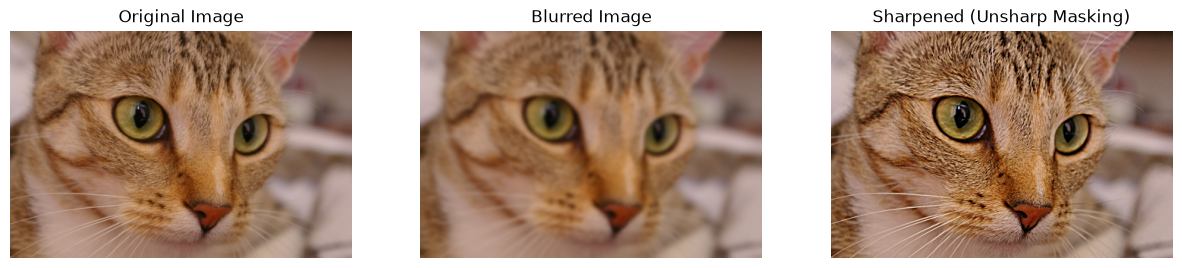

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

%matplotlib inline

image = data.chelsea()

sigma = 2
amount = 1.5

image_float = image.astype(np.float32) / 255.0

blurred = cv2.GaussianBlur(image_float, (0, 0), sigmaX=sigma, sigmaY=sigma)

sharpened = np.clip(image_float + amount * (image_float - blurred), 0, 1)

os.makedirs('output', exist_ok=True)
cv2.imwrite('output/chelsea.png', cv2.cvtColor(image, cv2.COLOR_RGB2BGR))
cv2.imwrite('output/unsharp_masking.png', cv2.cvtColor(np.uint8(sharpened * 255), cv2.COLOR_RGB2BGR))

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(image)
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(blurred)
ax[1].set_title("Blurred Image")
ax[1].axis("off")

ax[2].imshow(sharpened)
ax[2].set_title("Sharpened (Unsharp Masking)")
ax[2].axis("off")

plt.show()

**Observation:** The blurred image has no fine details. The sharpened image has stronger edges, and the fur texture and the eyes of the cat look a little crisper than in the original. If `amount` is too big, the edges get halos and noise.

## 2. Assessment

### Task 1: Smooth an image with a 7x7 box filter

A 7x7 box filter is a kernel of 49 ones divided by 49. Each output pixel is the average of the 7x7 pixels around it.

same result as cv2.blur: True


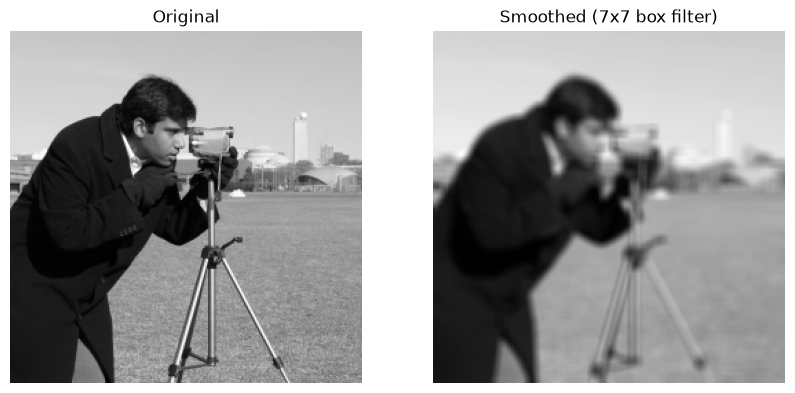

In [2]:
img = cv2.imread('../images/cameraman.tif', cv2.IMREAD_GRAYSCALE)

kernel = np.ones((7, 7), np.float32) / 49
smoothed = cv2.filter2D(img, -1, kernel)

print("same result as cv2.blur:", np.array_equal(smoothed, cv2.blur(img, (7, 7))))

cv2.imwrite('output/task1_box_7x7.png', smoothed)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(img, cmap='gray')
ax[0].set_title('Original')
ax[0].axis('off')

ax[1].imshow(smoothed, cmap='gray')
ax[1].set_title('Smoothed (7x7 box filter)')
ax[1].axis('off')

plt.show()

**Observation:** The smoothed image is blurred. The fine details and the noise are reduced, but the edges are blurred too.

### Task 2: Gaussian filters 5x5 and 21x21

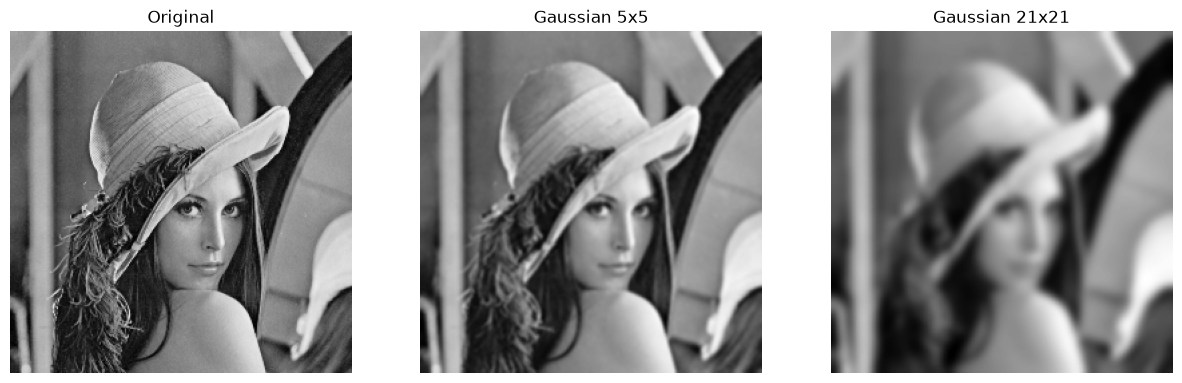

In [3]:
img = cv2.imread('../images/lena_gray_256.tif', cv2.IMREAD_GRAYSCALE)

gauss5 = cv2.GaussianBlur(img, (5, 5), 0)
gauss21 = cv2.GaussianBlur(img, (21, 21), 0)

cv2.imwrite('output/task2_gaussian_5x5.png', gauss5)
cv2.imwrite('output/task2_gaussian_21x21.png', gauss21)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(img, cmap='gray')
ax[0].set_title('Original')
ax[0].axis('off')

ax[1].imshow(gauss5, cmap='gray')
ax[1].set_title('Gaussian 5x5')
ax[1].axis('off')

ax[2].imshow(gauss21, cmap='gray')
ax[2].set_title('Gaussian 21x21')
ax[2].axis('off')

plt.show()

**Observation:** The 5x5 filter blurs the image a little and the image is still sharp enough. The 21x21 filter blurs it a lot and the small details are lost. A bigger kernel means more smoothing.

### Task 3: Sharpening with a 3x3 Laplacian filter

Steps:
1. Read the image
2. Convert it to float32
3. Use `cv2.Laplacian()`
4. Sharpen with `np.clip(image_float - laplacian, 0, 1)`
5. Plot the original, the Laplacian and the sharpened images

The center of the Laplacian kernel is negative, so I subtract the Laplacian from the image.

same as the 3x3 kernel: True


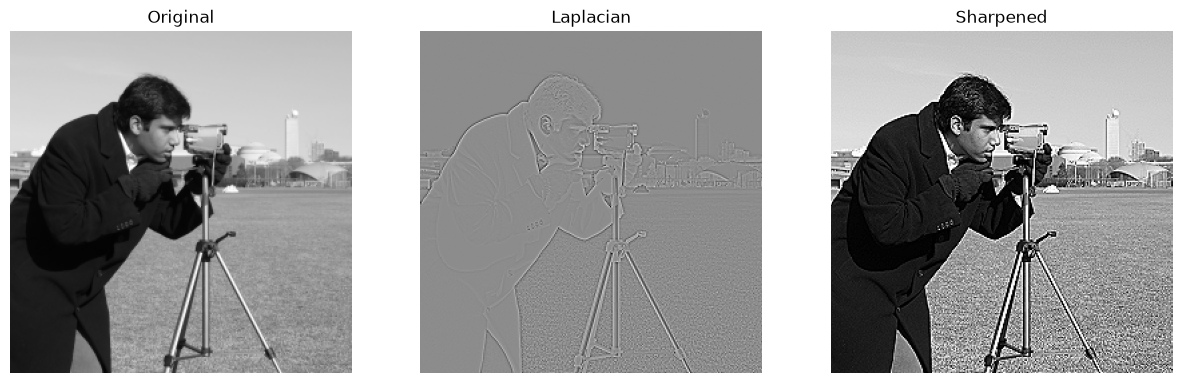

In [4]:
img = cv2.imread('../images/cameraman.tif', cv2.IMREAD_GRAYSCALE)

image_float = img.astype(np.float32) / 255.0

laplacian = cv2.Laplacian(image_float, cv2.CV_32F)

sharpened = np.clip(image_float - laplacian, 0, 1)

cv2.imwrite('output/task3_laplacian_sharpened.png', np.uint8(sharpened * 255))

kernel = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], np.float32)
print("same as the 3x3 kernel:", np.allclose(laplacian, cv2.filter2D(image_float, cv2.CV_32F, kernel)))

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(image_float, cmap='gray', vmin=0, vmax=1)
ax[0].set_title('Original')
ax[0].axis('off')

ax[1].imshow(laplacian, cmap='gray')
ax[1].set_title('Laplacian')
ax[1].axis('off')

ax[2].imshow(sharpened, cmap='gray', vmin=0, vmax=1)
ax[2].set_title('Sharpened')
ax[2].axis('off')

plt.show()

**Observation:** The Laplacian image is gray in the flat areas and shows only the edges (bright and dark lines). When I subtract it from the original, the edges get stronger and the image looks sharper.

## 3. Conclusion

- Smoothing filters (box and Gaussian) average the neighbor pixels. They reduce noise but blur the edges, and a bigger kernel blurs more.
- Sharpening filters (unsharp masking and Laplacian) make the edges stronger.
- The unsharp masking keeps the details of the blur difference, and the amount controls how strong the sharpening is.